# 03 · Ballenas y flujo de órdenes

**Objetivo:** pasar de velas a **operaciones individuales** para ver *quién*
mueve el mercado: el tamaño real de cada orden, si compra o vende de forma
agresiva y cómo se comporta el dinero grande frente al pequeño.

**Datos:** 30 días completos de `aggTrades` de BTCUSDT (23-oct a 21-nov 2026),
~31 millones de operaciones descargadas con `btc-trades --dias 30` desde
data.binance.vision y verificadas con su SHA-256.

**Contenido**
1. Qué es un aggTrade
2. Validación: ¿están todas las operaciones?
3. De aggTrades a órdenes reales
4. Distribución de tamaños: ¿cuánto pesa el dinero grande?
5. ¿Qué es una ballena? Umbral
6. Flujo por tamaño de orden
7. Flujo semana a semana: ¿quién vende a quién?
8. Ballenas en el gráfico y CVD
9. ¿Las ballenas anticipan el precio?
10. Conclusiones y limitaciones

## 1. Qué es un aggTrade

Cada vez que una orden **agresiva** (a mercado, *taker*) cruza contra órdenes
pasivas del libro (*maker*), Binance registra la ejecución. Un **aggTrade**
agrupa las ejecuciones de una misma orden agresiva **al mismo precio** y en el
mismo instante.

| Columna | Significado |
|---|---|
| `time` | Instante de la ejecución (UTC, precisión de microsegundos) |
| `price`, `quantity` | Precio y cantidad en BTC |
| `n_trades` | Ejecuciones individuales agrupadas |
| `compra_agresiva` | `True` si el agresor compró; `False` si vendió |

En el archivo original el lado viene como `is_buyer_maker` ("el comprador era
el pasivo"), que es justo lo contrario de "compra agresiva". El cliente lo
invierte al cargar para evitar confusiones.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.io as pio
import seaborn as sns
from scipy.stats import spearmanr

from btc_radar.agg_trades import cargar_trades, ultimos_dias
from btc_radar.ballenas import (
    agrupar_ordenes,
    cvd,
    delta_usd,
    detectar_ballenas,
    flujo_por_periodo,
    flujo_por_tamano,
    umbral_ballena,
    velas_desde_trades,
)
from btc_radar.datos import cargar_velas
from btc_radar.graficos import grafico_ballenas

pio.renderers.default = "plotly_mimetype+png"
sns.set_theme(style="whitegrid")

dias = ultimos_dias(30, hasta=date(2026, 11, 22))
trades = cargar_trades(dias)
print(f"{len(trades):,} aggTrades del {dias[0]} al {dias[-1]}")
print(f"Memoria: {trades.memory_usage(deep=True).sum() / 1e9:.2f} GB")
trades.head()

31,340,215 aggTrades del 2026-10-23 al 2026-11-21
Memoria: 1.28 GB


,agg_trade_id,time,price,quantity,n_trades,compra_agresiva
0,4095996431,2026-10-23 00:00:00.149088+00:00,81416.09,0.00026,1,True
1,4095996432,2026-10-23 00:00:00.178087+00:00,81416.08,0.00200,3,False
2,4095996433,2026-10-23 00:00:00.178204+00:00,81416.08,0.00200,1,False
3,4095996434,2026-10-23 00:00:00.178271+00:00,81416.08,0.00200,1,False
4,4095996435,2026-10-23 00:00:00.309047+00:00,81416.08,0.00200,1,False


## 2. Validación: ¿están todas las operaciones?

Dos comprobaciones independientes:
1. **IDs consecutivos:** `agg_trade_id` es correlativo; un salto indicaría
   operaciones perdidas.
2. **Cuadre con las velas:** la suma de cantidades por día debe coincidir con el
   volumen de la vela diaria descargada en la Fase 1 (fuente distinta: la API).

In [2]:
saltos = (trades["agg_trade_id"].diff().dropna() != 1).sum()
print(f"Saltos en agg_trade_id: {saltos}")

velas_1d = cargar_velas("1d")
dia = trades["time"].dt.floor("D")
compras = trades[trades["compra_agresiva"]]
cuadre = pd.DataFrame(
    {
        "volumen trades": trades.groupby(dia)["quantity"].sum(),
        "volumen velas": velas_1d["volume"],
        "compra trades": compras.groupby(dia[compras.index])["quantity"].sum(),
        "compra velas": velas_1d["taker_buy_volume"],
    }
).dropna()
dif_volumen = (cuadre["volumen trades"] / cuadre["volumen velas"] - 1).abs()
dif_compra = (cuadre["compra trades"] / cuadre["compra velas"] - 1).abs()
print(f"Días comparados: {len(cuadre)}")
print(f"Diferencia máxima en volumen: {dif_volumen.max():.6%}")
print(f"Diferencia máxima en compra agresiva: {dif_compra.max():.6%}")
cuadre.tail(3).round(3)

Saltos en agg_trade_id: 0


Días comparados: 30
Diferencia máxima en volumen: 0.000000%
Diferencia máxima en compra agresiva: 0.000000%


,volumen trades,volumen velas,compra trades,compra velas
2026-11-19 00:00:00+00:00,19879.640,19879.640,9339.066,9339.066
2026-11-20 00:00:00+00:00,38125.926,38125.926,17224.832,17224.832
2026-11-21 00:00:00+00:00,48558.101,48558.101,22529.434,22529.434


**Lectura:** no falta ningún ID y, en los 30 días, el volumen total y el
comprador cuadran con las velas al 0,000 %. Tenemos **todas** las operaciones
del periodo.

## 3. De aggTrades a órdenes reales

Una orden grande a mercado "barre" varios niveles del libro y queda registrada
como **un aggTrade por nivel**, todos con el mismo microsegundo y el mismo lado.
Si se analizan aggTrades sueltos, una orden de 5 M USD parece muchas pequeñas.
`agrupar_ordenes` vuelve a unirlas.

In [3]:
ordenes = agrupar_ordenes(trades)
print(
    f"{len(trades):,} aggTrades → {len(ordenes):,} órdenes "
    f"({len(ordenes) / len(trades):.0%})"
)

columnas = [
    "time",
    "usd",
    "cantidad",
    "compra_agresiva",
    "niveles",
    "precio_min",
    "precio_max",
]
ordenes.nlargest(8, "usd")[columnas].round({"usd": 0, "cantidad": 1})

31,340,215 aggTrades → 17,500,987 órdenes (56%)


,time,usd,cantidad,compra_agresiva,niveles,precio_min,precio_max
3434179,2026-10-29 16:13:19.504871+00:00,8168682.0,100.1,False,1081,81523.42,81706.22
1978588,2026-10-27 06:01:41.086959+00:00,7721101.0,96.7,False,560,79784.00,79930.48
6458724,2026-11-04 14:25:00.113770+00:00,7252622.0,92.5,False,1,78400.00,78400.00
8463170,2026-11-08 22:00:27.418465+00:00,6922646.0,93.2,True,1,74300.00,74300.00
14211247,2026-11-17 13:07:48.855497+00:00,6784586.0,104.1,True,370,65120.01,65184.01
15083584,2026-11-19 03:34:52.713608+00:00,6410654.0,101.7,True,3,63059.98,63060.00
15183463,2026-11-19 11:34:27.315921+00:00,6380485.0,99.6,True,1,64060.00,64060.00
12365390,2026-11-14 23:49:58.008240+00:00,6359668.0,99.3,True,1,64050.00,64050.00


**Lectura:** la agrupación reduce las filas casi a la mitad. La orden más
grande del mes (8,2 M USD, ~100 BTC, **venta** del 29-oct) consumió **1.081
niveles de precio** en un solo instante. Sin agrupar, habría aparecido como
más de mil operaciones medianas.

*Supuesto:* dos agresores distintos ejecutando en el mismo microsegundo y del
mismo lado se contarían como una sola orden. Es poco frecuente y no altera las
conclusiones.

## 4. Distribución de tamaños: ¿cuánto pesa el dinero grande?

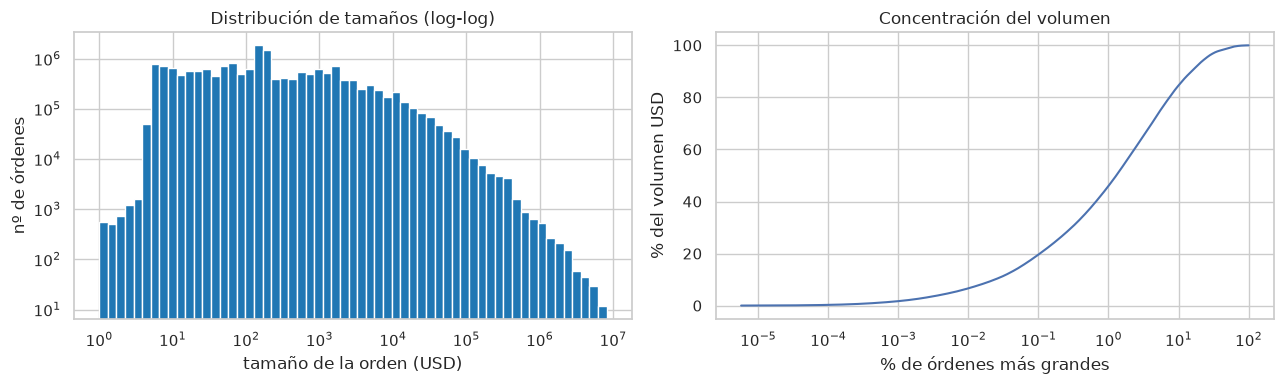

Mediana: 161 USD por orden


,% del volumen USD
top 0.1 %,19.6 %
top 1 %,46.0 %
top 10 %,84.6 %


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

bins = np.logspace(0, np.log10(ordenes["usd"].max()), 60)
axes[0].hist(ordenes["usd"], bins=bins, color="tab:blue")
axes[0].set(
    xscale="log",
    yscale="log",
    xlabel="tamaño de la orden (USD)",
    ylabel="nº de órdenes",
    title="Distribución de tamaños (log-log)",
)

ordenado = ordenes["usd"].sort_values(ascending=False).to_numpy()
pct_ordenes = np.arange(1, len(ordenado) + 1) / len(ordenado) * 100
pct_volumen = ordenado.cumsum() / ordenado.sum() * 100
axes[1].plot(pct_ordenes, pct_volumen)
axes[1].set(
    xscale="log",
    xlabel="% de órdenes más grandes",
    ylabel="% del volumen USD",
    title="Concentración del volumen",
)
plt.tight_layout()
plt.show()

print(f"Mediana: {ordenes['usd'].median():,.0f} USD por orden")
pd.Series(
    {
        f"top {p} %": f"{pct_volumen[int(len(ordenado) * p / 100) - 1]:.1f} %"
        for p in (0.1, 1, 10)
    }
).to_frame("% del volumen USD")

**Lectura:** muchísimas órdenes diminutas (mediana ≈ 160 USD) y unas pocas
enormes. Entre ~5 y ~1.000 USD la distribución es casi plana, con picos en
tamaños redondos, probablemente órdenes automatizadas o mínimos de la
plataforma. A partir de ~1.000 USD cae casi en línea recta en log-log: una
**cola pesada** de tipo ley de potencias.

El **0,1 % de las órdenes más grandes mueve ~20 % del volumen**, y el 1 % más
grande, casi la mitad.

## 5. ¿Qué es una ballena? Umbral

Dos criterios complementarios:
- **Relativo (percentil 99,9):** el 0,1 % de órdenes más grandes del periodo. Se
  adapta a cada época del mercado.
- **Absoluto (≥ 1 M USD):** fácil de comunicar y estable entre periodos.

In [5]:
umbral = umbral_ballena(ordenes, percentil=0.999)
ballenas = detectar_ballenas(ordenes, percentil=0.999)
ballenas_1m = detectar_ballenas(ordenes, umbral_usd=1e6)


def resumen(grupo: pd.DataFrame, umbral_usd: float) -> list:
    return [
        f"{umbral_usd:,.0f}",
        len(grupo),
        f"{grupo['compra_agresiva'].mean():.1%}",
        f"{delta_usd(grupo).sum() / 1e6:+.1f}",
    ]


pd.DataFrame(
    {
        "percentil 99,9": resumen(ballenas, umbral),
        "≥ 1 M USD": resumen(ballenas_1m, 1e6),
    },
    index=["umbral (USD)", "órdenes", "% compras", "delta neto (M USD)"],
)

,"percentil 99,9",≥ 1 M USD
umbral (USD),"195,378","1,000,000"
órdenes,17501,1071
% compras,48.1%,45.4%
delta neto (M USD),-242.8,-130.2


## 6. Flujo por tamaño de orden

¿Quién compra y quién vende? `delta %` es el delta del grupo sobre su volumen:
+100 % si todo fue compra agresiva, −100 % si todo fue venta agresiva.

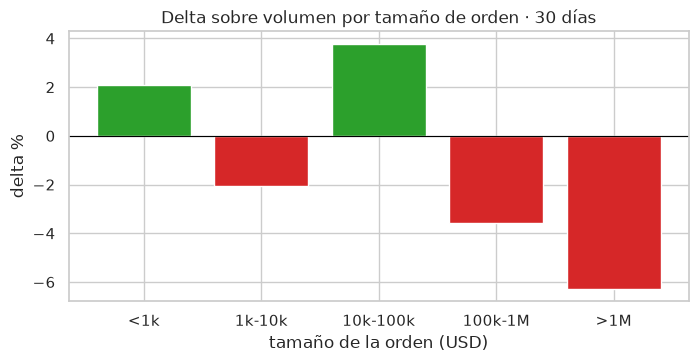

Precio: 81,416 → 60,216 (-26.0%), mínimo 55,130


,órdenes,volumen (M USD),% del volumen,delta (M USD),delta %
tamano,,,,,
<1k,13610659,2359.2,5.9,49.4,2.1
1k-10k,3154315,9639.9,23.9,-198.1,-2.1
10k-100k,695074,17247.0,42.8,652.3,3.8
100k-1M,39868,8993.7,22.3,-320.1,-3.6
>1M,1071,2074.6,5.1,-130.2,-6.3


In [6]:
flujo = flujo_por_tamano(ordenes)
tabla = pd.DataFrame(
    {
        "órdenes": flujo["ordenes"],
        "volumen (M USD)": flujo["volumen_usd"] / 1e6,
        "% del volumen": flujo["volumen_pct"] * 100,
        "delta (M USD)": flujo["delta_usd"] / 1e6,
        "delta %": flujo["delta_pct"] * 100,
    }
)

fig, ax = plt.subplots(figsize=(8, 3.5))
colores = np.where(tabla["delta %"] >= 0, "tab:green", "tab:red")
ax.bar(tabla.index.astype(str), tabla["delta %"], color=colores)
ax.axhline(0, color="black", lw=0.8)
ax.set(
    title="Delta sobre volumen por tamaño de orden · 30 días",
    xlabel="tamaño de la orden (USD)",
    ylabel="delta %",
)
plt.show()

print(
    f"Precio: {trades['price'].iloc[0]:,.0f} → {trades['price'].iloc[-1]:,.0f} "
    f"({trades['price'].iloc[-1] / trades['price'].iloc[0] - 1:+.1%}), "
    f"mínimo {trades['price'].min():,.0f}"
)
tabla.round(1)

**Lectura:** en un mes en el que BTC cayó ~26 % (de ~81.400 a ~60.200, con
mínimo en 55.130 el 21-nov):
- Las órdenes **> 1 M USD** fueron **vendedoras netas** (−6,3 % de su volumen)
  y las de 100k-1M también (−3,6 %).
- Las órdenes **< 1.000 USD** fueron ligeramente **compradoras** (+2,1 %).

En el agregado del mes, el dinero grande vendió y el pequeño compró. Pero el
agregado esconde un cambio de comportamiento → sección 7.

## 7. Flujo semana a semana: ¿quién vende a quién?

`flujo_por_periodo` calcula el delta % de cada grupo en cada semana. Se agrupan
en minoristas (< 10k USD), medianas (10k-1M) y ballenas (> 1M).

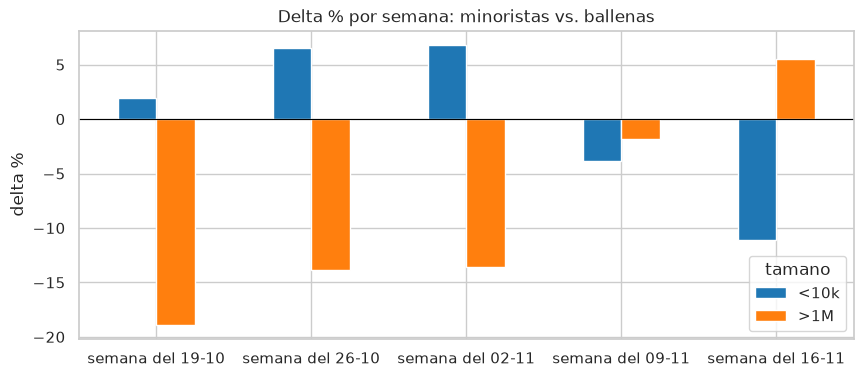

tamano,<10k,10k-1M,>1M,retorno precio %
periodo,,,,
2026-10-19/2026-10-25,1.9,-3.4,-18.9,-1.6
2026-10-26/2026-11-01,6.5,7.5,-13.8,-2.3
2026-11-02/2026-11-08,6.8,0.4,-13.6,-4.2
2026-11-09/2026-11-15,-3.9,-1.4,-1.9,-13.1
2026-11-16/2026-11-22,-11.1,1.0,5.5,-7.3


In [7]:
semanal = flujo_por_periodo(ordenes, frecuencia="W") * 100

cierre_1h = velas_desde_trades(trades, "1h")["close"]
semanas = cierre_1h.index.tz_localize(None).to_period("W")
precio_semanal = cierre_1h.groupby(semanas).agg(["first", "last"])
semanal["retorno precio %"] = (
    precio_semanal["last"] / precio_semanal["first"] - 1
) * 100

inicio_semana = [f"semana del {p.start_time:%d-%m}" for p in semanal.index]
fig, ax = plt.subplots(figsize=(10, 4))
semanal[["<10k", ">1M"]].set_axis(inicio_semana).plot.bar(
    ax=ax, color=["tab:blue", "tab:orange"], rot=0
)
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Delta % por semana: minoristas vs. ballenas", ylabel="delta %")
plt.show()

semanal.round(1)

**Lectura:** el comportamiento **se invierte** a lo largo del mes:

| Tramo | Precio | Minoristas (< 10k) | Ballenas (> 1M) |
|---|---|---|---|
| 3 primeras semanas | Caída lenta (−2 % a −4 % semanal) | **Compran** (+2 % a +7 %) | **Venden** fuerte (−14 % a −19 %) |
| Semana del 9-nov | Caída fuerte (−13 %) | Empiezan a vender | Casi neutras |
| Semana del 16-nov | Caída y mínimo en 55k | **Venden** (−11 %) | **Compran** (+5,5 %) |

Leído con Wyckoff: durante semanas las ballenas **distribuyeron** (vendieron a
los minoristas que compraban la caída); después vino la caída fuerte
(*markdown*); y en el pánico final los minoristas vendieron y las ballenas
volvieron a comprar (**absorción**, posible clímax de venta).

**Por qué importa haber pasado de 7 a 30 días:** con una sola semana parecía que
las ballenas solo compraban. El mes completo muestra que antes vendieron mucho
más de lo que después recompraron (delta neto de las órdenes > 1M en el mes:
≈ −130 M USD). Es una hipótesis a validar con más datos, no una regla.

## 8. Ballenas en el gráfico y CVD

**CVD** (*Cumulative Volume Delta*): suma acumulada de compras agresivas menos
ventas agresivas. Si baja, dominan los vendedores agresivos.

Con 30 días se usan velas de 4h y se representan las órdenes ≥ 1 M USD.

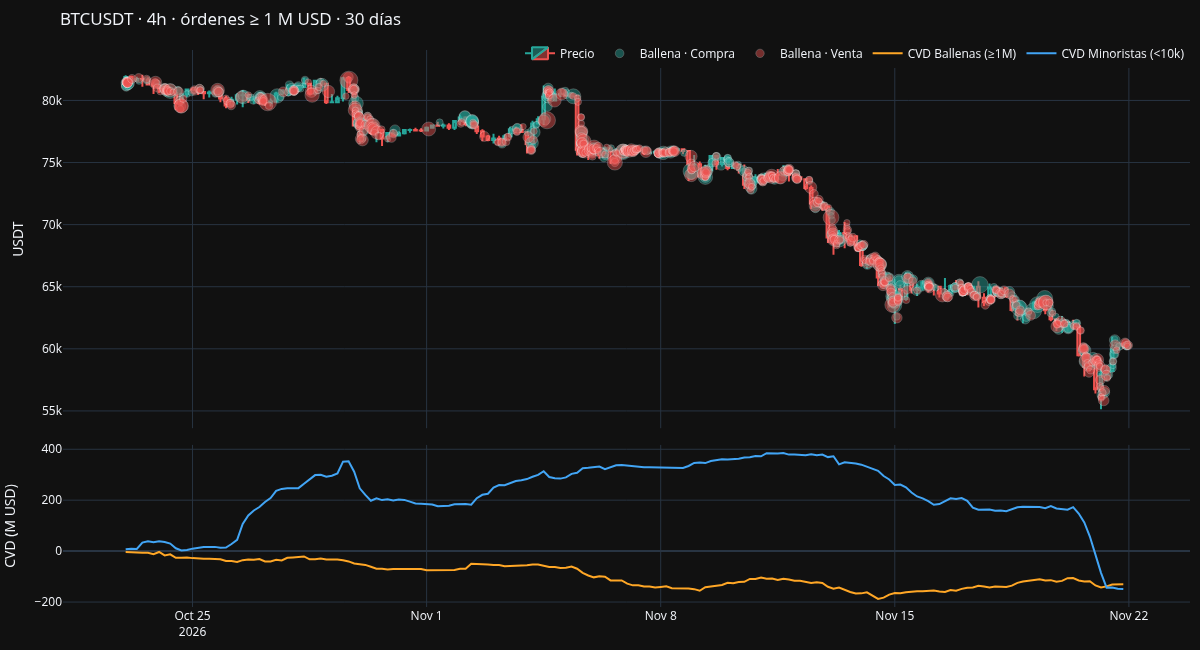

In [8]:
velas_4h = velas_desde_trades(trades, "4h")
minoristas = ordenes[ordenes["usd"] < 1e4]
cvds = {
    "Ballenas (≥1M)": cvd(ballenas_1m, "4h"),
    "Minoristas (<10k)": cvd(minoristas, "4h"),
}

grafico_ballenas(
    velas_4h,
    ballenas_1m,
    cvds,
    "BTCUSDT · 4h · órdenes ≥ 1 M USD · 30 días",
    tamano_max=18,  # burbujas pequeñas: son más de mil órdenes
).show(width=1200, height=650)

**Lectura:**
- El CVD de las **ballenas** baja de forma sostenida durante las tres primeras
  semanas (distribución) y se aplana o repunta en la última.
- El CVD de los **minoristas** sube mientras las ballenas venden y se desploma
  en la caída del 20-21 de noviembre.
- En el **mínimo** del 21-nov aparecen ventas grandes (burbujas rojas) y el
  **rebote** posterior arranca con compras grandes (burbujas verdes).

## 9. ¿Las ballenas anticipan el precio?

Test por horas: correlación de rangos (Spearman) entre el delta de cada grupo
en una hora y el retorno **de esa misma hora** y **de la hora siguiente**.

In [9]:
precio = cierre_1h
retorno = np.log(precio).diff()


def delta_horario(grupo: pd.DataFrame) -> pd.Series:
    serie = delta_usd(grupo).set_axis(grupo["time"]).resample("1h").sum()
    return serie.reindex(precio.index, fill_value=0)


grupos = [
    ("ballenas (p99,9)", ballenas),
    ("ballenas (≥1M)", ballenas_1m),
    ("minoristas (<10k)", minoristas),
]
filas = {}
for nombre, grupo in grupos:
    delta = delta_horario(grupo)
    mismo = spearmanr(delta, retorno, nan_policy="omit")
    siguiente = spearmanr(delta, retorno.shift(-1), nan_policy="omit")
    filas[nombre] = {
        "ρ misma hora": round(mismo.statistic, 2),
        "p misma hora": f"{mismo.pvalue:.1g}",
        "ρ hora siguiente": round(siguiente.statistic, 2),
        "p hora siguiente": round(siguiente.pvalue, 2),
    }
print(f"Horas analizadas: {retorno.notna().sum()}")
pd.DataFrame(filas).T

Horas analizadas: 719


,ρ misma hora,p misma hora,ρ hora siguiente,p hora siguiente
"ballenas (p99,9)",0.32,8e-19,-0.01,0.74
ballenas (≥1M),0.14,0.0001,0.01,0.72
minoristas (<10k),0.2,1e-07,-0.04,0.29


**Lectura:**
- El flujo de las ballenas **acompaña** al precio en la misma hora (ρ ≈ 0,3,
  muy significativo): cuando compran, el precio sube en esa hora.
- Pero **no anticipa** la hora siguiente (ρ ≈ 0, p-valor alto), ni con el
  umbral relativo ni con el de 1 M USD.
- Con 7 días aparecía una ligera relación inversa entre el flujo minorista y la
  hora siguiente (p ≈ 0,07). Con 30 días **desaparece**: era ruido de una
  muestra pequeña.

**Conclusión:** a corto plazo (1 hora) seguir el flujo de las ballenas no da
ventaja. Su valor está en el **contexto** de varios días o semanas (sección 7),
que es justo la escala en la que trabaja Wyckoff.

## 10. Conclusiones y limitaciones

**Conclusiones**
1. **Datos completos y validados:** 31 M de aggTrades en 30 días, sin huecos,
   que cuadran exactamente con las velas.
2. **Agrupar en órdenes es necesario:** reduce las filas a algo más de la mitad
   y revela órdenes de hasta 8,2 M USD que barren más de mil niveles.
3. **Cola pesada:** el 0,1 % de las órdenes mueve ~20 % del dinero.
4. **Distribución y absorción:** durante tres semanas las ballenas vendieron
   mientras los minoristas compraban; en el pánico final se invirtieron los
   papeles.
5. **Sin ventaja predictiva a 1 hora:** el flujo de ballenas es útil como
   contexto de días o semanas, no como señal inmediata.

**Limitaciones**
- Solo Binance **spot**: no incluye futuros (donde se negocia más volumen) ni
  otros exchanges.
- Un mes de datos en un único régimen (mercado bajista): los hallazgos son
  descriptivos.
- Las órdenes **pasivas** grandes (muros del libro) no aparecen en las
  operaciones; requieren el libro de órdenes (fase opcional 9).

**Siguiente paso → Fase 5:** detectar rangos y eventos Wyckoff por reglas,
usando volumen, volatilidad y el flujo de órdenes como evidencia.